<a href="https://colab.research.google.com/github/ChinmyeeN/MinorProject/blob/main/MP2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [9]:
df = pd.read_csv("/content/House Price Prediction Dataset.csv")

In [10]:
df.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [11]:
df.tail()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119
1999,2000,2989,5,1,3,1903,Suburban,Fair,No,482525


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         2000 non-null   int64 
 1   Area       2000 non-null   int64 
 2   Bedrooms   2000 non-null   int64 
 3   Bathrooms  2000 non-null   int64 
 4   Floors     2000 non-null   int64 
 5   YearBuilt  2000 non-null   int64 
 6   Location   2000 non-null   object
 7   Condition  2000 non-null   object
 8   Garage     2000 non-null   object
 9   Price      2000 non-null   int64 
dtypes: int64(7), object(3)
memory usage: 156.4+ KB


In [13]:
df.isnull().sum()


,0
Id,0
Area,0
Bedrooms,0
Bathrooms,0
Floors,0
YearBuilt,0
Location,0
Condition,0
Garage,0
Price,0


In [14]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='Price', ylabel='Density'>

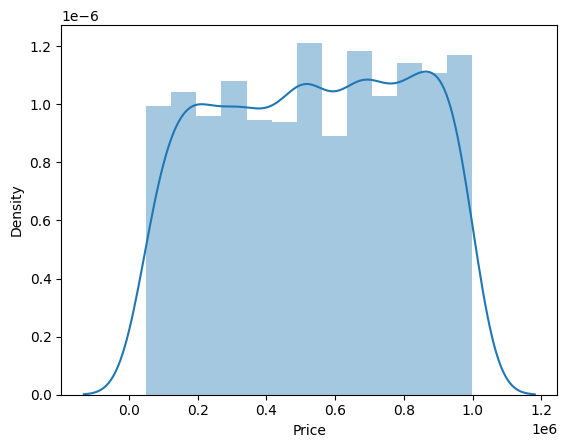

In [15]:
sns.distplot(df['Price'])

In [16]:
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['Price'] >= lower_bound) & (df['Price'] <= upper_bound)]

In [17]:
df['Price'] = df['Price'].clip(lower_bound, upper_bound)

<Axes: xlabel='Price', ylabel='Density'>

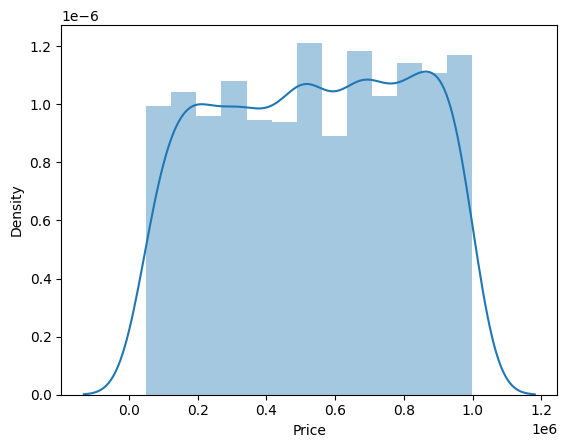

In [18]:
sns.distplot(df['Price'])

<Axes: xlabel='Area', ylabel='Price'>

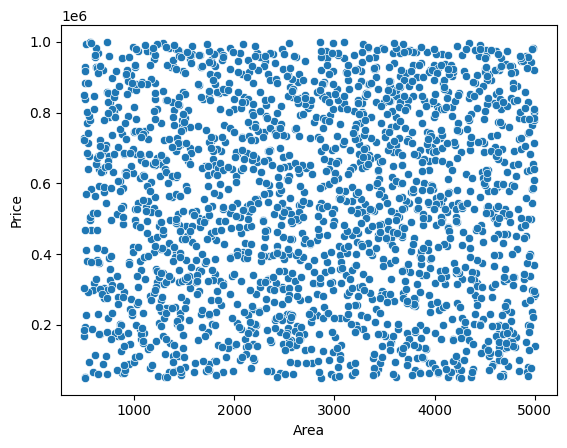

In [19]:
sns.scatterplot(x = 'Area', y = 'Price', data = df)

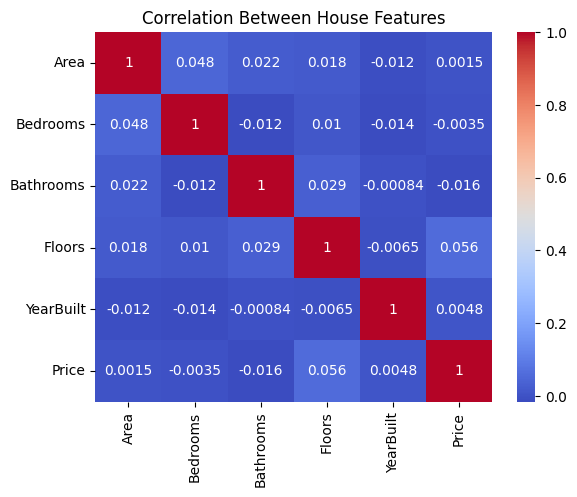

In [20]:
sns.heatmap(df[['Area', 'Bedrooms', 'Bathrooms',
                'Floors', 'YearBuilt', 'Price']].corr(),
            annot=True, cmap='coolwarm')

plt.title("Correlation Between House Features")
plt.show()

In [29]:
X = df.drop(['Price', 'Id','Location','Condition','Garage'], axis=1)
y = df['Price']

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [33]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [34]:
y_pred = model.predict(X_test)

In [35]:
print(y_pred)

[515577.20094333 544286.23995207 504412.67222196 555773.69096497
 568830.77263034 550559.76495508 551103.35655728 545058.55449332
 563718.90528357 569110.12168438 543408.11534439 571633.99915652
 501424.22862705 531083.34430071 516815.92882169 531649.07139353
 550670.60701054 548996.57393676 558062.53287805 516375.07054634
 540824.97530992 524811.22526431 523878.15245573 570734.57058341
 551929.04280674 537594.89375093 516770.32916229 515025.41577357
 534186.65880006 494752.5305287  502193.06983099 549929.55971921
 549744.44960267 571036.1548647  523634.48561239 491910.99108597
 565251.1836073  578941.90662208 522943.37401475 517502.96686275
 494456.62682314 521391.09703124 528750.69360737 537077.43049002
 543840.37812118 541329.78616017 553358.79049608 516553.04308789
 547090.05760156 531771.98597726 496727.98955755 527229.37870637
 561409.92528337 540154.38373792 529347.18682494 520818.51760172
 566181.5170467  494819.01229341 504556.13308245 516628.93645732
 546527.71275712 504195.1

In [36]:
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(results)

      Actual      Predicted
1860  514764  515577.200943
353   694256  544286.239952
1333   66375  504412.672222
905   650243  555773.690965
1289  223285  568830.772630
...      ...            ...
965   386940  556358.712145
1284  632570  548055.892093
1739  494049  518877.978887
261   562193  535501.877261
535   447530  572150.738293

[400 rows x 2 columns]


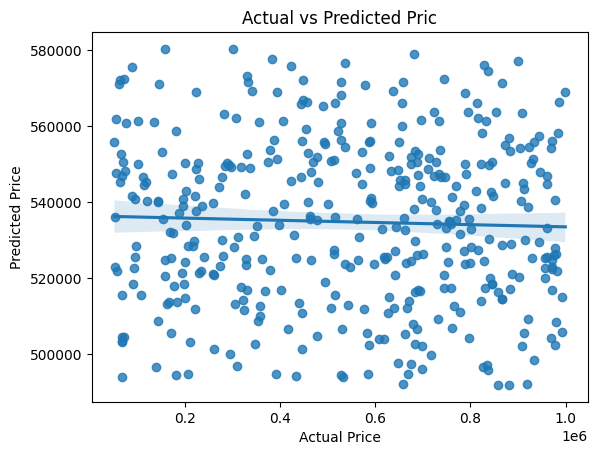

In [38]:
sns.regplot(x = y_test, y = y_pred,data = df)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Pric')
plt.show()

In [39]:
print("slope:",model.coef_[0])
print("Intercept:",model.intercept_)

slope: -0.356815605576153
Intercept: 294999.8413069162


In [40]:
r2 = r2_score(y_test, y_pred)
print("R-squared:", r2)

R-squared: -0.01273663755401877


In [41]:
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 78789724000.88458
